In [10]:
import numpy as np
rng=np.random.default_rng(seed=11)
# with seed, every time generate the same random variable, reproduciable 
# initialize the generator 
single_float=rng.random()
print(f"single_float,{single_float}\n")
float_array=rng.random((3,3))
print(f"float_array,{float_array}\n")
integers=rng.integers(low=1,high=11,size=(5,))
print(f"integers,{integers}\n")
normal_samples=rng.normal(loc=0.0,scale=1.0,size=10)
print(f"normal_samples,{normal_samples}\n")
items=np.array([10,20,30,40,50])
rng.shuffle(items)
# directly mutates on the original items array
shuffled_items=rng.permutation(items)
# return a new array, reamin the original untouched 
print(f"shuffle,{items}")
print(shuffled_items)

single_float,0.12857020276919962

float_array,[[0.49927786 0.60149836 0.02868901]
 [0.14792608 0.92821102 0.07042058]
 [0.12977395 0.94832845 0.62188359]]

integers,[9 4 2 6 5]

normal_samples,[-0.13656633 -0.37909857  0.46311016  0.82451353 -0.20252987 -0.15278618
  0.68569861 -0.87034064 -1.5143835   0.39498186]

shuffle,[30 20 10 50 40]
[20 30 50 10 40]


In [11]:
import pandas as pd
base=rng.normal(loc=10,scale=2,size=200)
noise=rng.normal(loc=0,scale=1,size=200)
data={"feature_A": base,
      "feature_B": base*2.5 + noise,
      "feature_C": -base*1.8 + noise,
      "feature_D": rng.normal(loc=5,scale=5,size=200),
      "feature_E": rng.uniform(low=-10,high=10,size=200),
      }
df=pd.DataFrame(data)
print(df)

     feature_A  feature_B  feature_C  feature_D  feature_E
0     7.613595  17.559597 -15.178861  -3.308808  -6.874316
1     7.015072  16.021122 -14.143688   8.741119  -9.833327
2    10.073276  24.239925 -19.075161  15.815483   7.072928
3    11.794499  30.311844 -20.404500  -2.406879   4.341142
4     9.533736  25.500381 -15.494683  14.099249   5.043997
..         ...        ...        ...        ...        ...
195  10.179057  25.613508 -18.156437  -0.370360   0.747012
196   5.365564  12.210089 -10.861834   4.081567   0.550042
197  10.383230  24.694138 -19.953749  -1.393476   9.593454
198   7.940782  19.970534 -14.174827  13.150870  -9.125559
199   8.605203  21.434793 -15.567579  -0.094562  -4.046328

[200 rows x 5 columns]


In [12]:
cov_matrix=df.cov()
# unbounded (-infinite,infinite)
# tells direction of the linear relationship, but does not tell the strength
print(cov_matrix)
# diagonal: variance of each individual feature (always positive)--> larger diagonal values means wider spread
# off diagonal: positive values-> positive proportion; negative values-> negative proportion; near 0 or =0-> not correlated 
                # the highest absolute value means the corresponding feature are measured on similar scales.

           feature_A  feature_B  feature_C  feature_D  feature_E
feature_A   3.399262   8.675720  -5.941105   1.288971   1.329754
feature_B   8.675720  23.123275 -14.182321   3.399433   3.192620
feature_C  -5.941105 -14.182321  11.364429  -2.143141  -2.525323
feature_D   1.288971   3.399433  -2.143141  26.496756   1.191670
feature_E   1.329754   3.192620  -2.525323   1.191670  28.755577


In [13]:
mask=np.triu(np.ones_like(cov_matrix,dtype=bool))
# np.triu: upper triangle 
# create a new array with exact same dimensions as corr_matrix 
# np.ones_like and dtype=bool makes the matrix initialized to all ones
# 1. np.ones_like(..., dtype=bool)
# [[True, True, True],
#  [True, True, True],
#  [True, True, True]]

# 2. Wrapped in np.triu(...)
# [[True,  True,  True],
#  [False, True,  True],
#  [False, False, True]]

<Axes: >

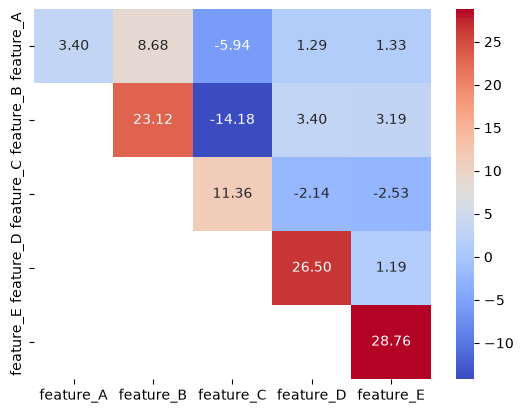

In [14]:
import seaborn as sns
sns.heatmap(cov_matrix,
            annot=True, #display the value in each cell
            fmt=".2f", #format to 2 decimal places
            cmap="coolwarm", #color map
            mask=~mask,
            )

In [15]:
# correlation is standardized version of covariance # diagonal consists entirely of 1
# tells both direction and strength of the linear relationship
corr_matrix=df.corr()
print(corr_matrix)

           feature_A  feature_B  feature_C  feature_D  feature_E
feature_A   1.000000   0.978562  -0.955875   0.135817   0.134499
feature_B   0.978562   1.000000  -0.874881   0.137336   0.123812
feature_C  -0.955875  -0.874881   1.000000  -0.123504  -0.139695
feature_D   0.135817   0.137336  -0.123504   1.000000   0.043172
feature_E   0.134499   0.123812  -0.139695   0.043172   1.000000


In [16]:
mask=np.triu(np.ones_like(corr_matrix,dtype=bool))
# np.triu: upper triangle 
# create a new array with exact same dimensions as corr_matrix 
# np.ones_like and dtype=bool makes the matrix initialized to all ones
# 1. np.ones_like(..., dtype=bool)
# [[True, True, True],
#  [True, True, True],
#  [True, True, True]]

# 2. Wrapped in np.triu(...)
# [[True,  True,  True],
#  [False, True,  True],
#  [False, False, True]]

<Axes: >

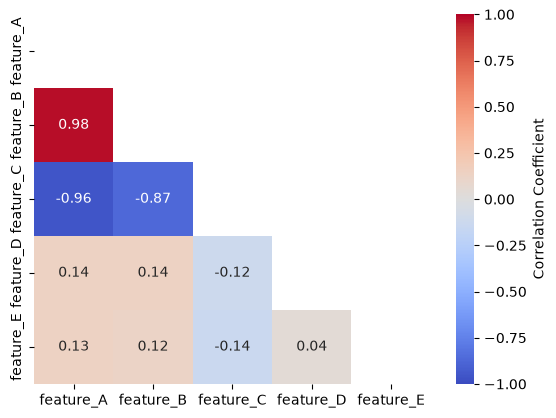

In [17]:
sns.heatmap(corr_matrix,
            mask=mask,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            vmin=-1, #set anchor for min color scale
            vmax=1,
            cbar_kws={"label":"Correlation Coefficient"}
            )